# Unsupervised Microscopy Image Segmentation with K-Means
### Independent academic project · Beginner-friendly · Kaggle CPU notebook

**Research question:** How do simple unsupervised intensity-clustering methods compare with an automatic thresholding baseline for identifying bright cell-like regions?

We compare **Otsu**, **K-Means (K=2)** and **K-Means (K=3)**. We test segmentation accuracy on **six generated microscopy-style scenes** (three clean, three noisy) with exact reference masks, and visually inspect **one real microscopy image** with *no* ground-truth mask.

**Important:** We do **not** claim clinical diagnostic capability or quantitative segmentation accuracy on the real microscopy image. Synthetic shapes are not real biological samples.

**Kaggle setup:** Python notebook · CPU · Internet **Off** · no dataset attachment necessary. Select **Run All** or **Save Version → Save & Run All**. Figures and metrics are saved under `/kaggle/working/microscopy_kmeans_outputs` (or `outputs/microscopy_kmeans_outputs` when run locally).

## 1. Environment and reproducibility

This notebook is self-contained. Its real image is the `skimage.data.cell()` sample distributed with scikit-image, and synthetic images are produced with a fixed random seed. We rely on packages ordinarily available in Kaggle Python environments; no `pip install` cell or external download is needed.

In [1]:
from __future__ import annotations

import json
import platform
from pathlib import Path
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import skimage
from scipy.ndimage import gaussian_filter
from skimage import data, filters, morphology, transform
from skimage.draw import ellipse
from sklearn.cluster import KMeans

SEED = 42
METHODS = ('Otsu', 'KMeans-2', 'KMeans-3')

from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Avoid excessive BLAS threads on shared Kaggle CPUs
from IPython.display import display, Image

OUTPUT = (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd() / 'outputs') / 'microscopy_kmeans_outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Save location:', OUTPUT)
print('scikit-learn:', sklearn.__version__, '| scikit-image:', skimage.__version__)

Save location: /mnt/data/kaggle_notebooks_ready/outputs/microscopy_kmeans_outputs
scikit-learn: 1.8.0 | scikit-image: 0.26.0


## 2. Data: microscopy image and simulated reference masks

We load one **real** grayscale specimen image for visual assessment. For quantitative testing, we create four bright elliptical shapes on a nonuniform background with Gaussian blur and noise. The exact binary locations of the generated shapes are known, so performance metrics are possible only for these controlled synthetic images.

The generated scenes are deliberately easy. High scores on them should **not** be generalized to real cell segmentation.

In [2]:
def synthetic_scene(seed: int, condition: str = 'clean') -> tuple[np.ndarray, np.ndarray]:
    """Make microscopy-*style* bright ellipses with exact binary reference mask.

    These are synthetic shapes, NOT biological specimens or manual annotations.
    """
    if condition not in ('clean', 'noisy'):
        raise ValueError('condition must be clean or noisy')
    rng = np.random.default_rng(seed)
    h, w = 256, 256
    truth = np.zeros((h, w), dtype=bool)
    signal = np.zeros((h, w), dtype=float)
    centers = [(62, 64), (65, 190), (178, 67), (186, 187)]
    for cy, cx in centers:
        cy += int(rng.integers(-7, 8))
        cx += int(rng.integers(-7, 8))
        ry = int(rng.integers(17, 27))
        rx = int(rng.integers(16, 27))
        rr, cc = ellipse(cy, cx, ry, rx, shape=(h, w))
        truth[rr, cc] = True
        signal[rr, cc] = rng.uniform(0.63, 0.89)

    yy, xx = np.indices((h, w))
    spatial_gradient = (xx / (w-1) - 0.5) * (0.08 if condition == 'clean' else 0.22)
    background = 0.15 + spatial_gradient + 0.02 * np.sin(yy / 35.0)
    blurred_cells = gaussian_filter(signal, sigma=1.15)
    noise_sigma = 0.025 if condition == 'clean' else 0.09
    image = background + blurred_cells + rng.normal(0, noise_sigma, (h, w))
    return np.clip(image, 0.0, 1.0).astype(np.float32), truth


def real_cell_image() -> np.ndarray:
    """Bundled microscopy image resized for a fast CPU-based demonstration."""
    image = data.cell()
    resized = transform.resize(image, (330, 275), anti_aliasing=True)
    return np.asarray(resized, dtype=np.float32)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


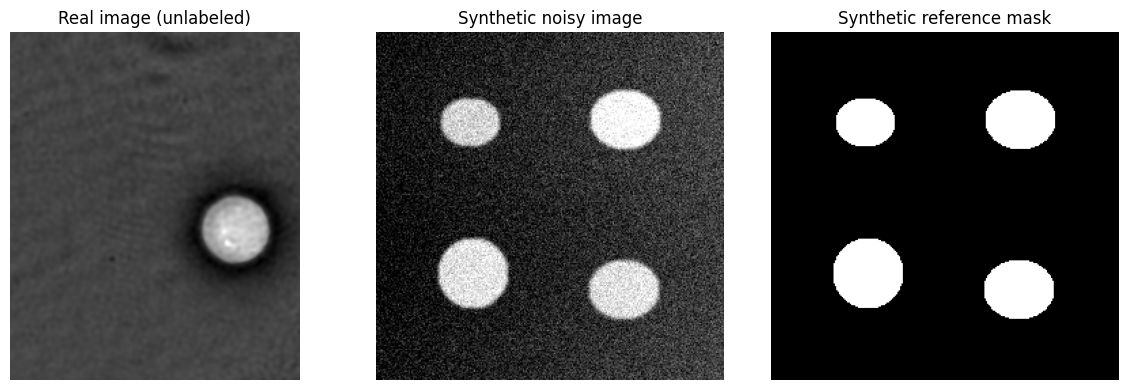

Real image: (330, 275) | Synthetic image: (256, 256)


In [3]:
real_image = real_cell_image()
synthetic_image, synthetic_truth = synthetic_scene(seed=100, condition='noisy')
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(real_image, cmap='gray'); axs[0].set_title('Real image (unlabeled)')
axs[1].imshow(synthetic_image, cmap='gray'); axs[1].set_title('Synthetic noisy image')
axs[2].imshow(synthetic_truth, cmap='gray'); axs[2].set_title('Synthetic reference mask')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()
print('Real image:', real_image.shape, '| Synthetic image:', synthetic_image.shape)

## 3. Segmentation algorithms and metrics

1. **Otsu thresholding:** selects a binary global threshold from the image histogram.
2. **K-Means K=2:** assigns grayscale pixels to two intensity clusters; the brighter cluster represents foreground.
3. **K-Means K=3:** assigns three intensity clusters; again we take only the brightest as foreground. This design choice can discard intermediate-brightness object pixels.

All methods use **the same Gaussian smoothing and morphological cleanup**. K-Means is unsupervised: reference masks never enter the clustering step. We calculate **Dice**, **Intersection over Union (IoU)**, **precision**, and **recall** against synthetic masks only.

$\mathrm{Dice} = \frac{2TP}{2TP+FP+FN}$; $\mathrm{IoU} = \frac{TP}{TP+FP+FN}$.

In [4]:
def postprocess(mask: np.ndarray) -> np.ndarray:
    """Identical morphological cleanup for all methods."""
    result = morphology.area_opening(mask.astype(bool), area_threshold=35)
    result = morphology.closing(result, footprint=morphology.disk(2))
    result = morphology.area_closing(result, area_threshold=40)
    return np.asarray(result, dtype=bool)


def segment(image: np.ndarray, method: str) -> tuple[np.ndarray, float]:
    """Generate a binary foreground mask (bright cells), tracking wall-clock runtime.

    KMeans learns brightness centers from every fourth smoothed pixel.
    Brightest cluster is the foreground for BOTH real and synthetic images.
    There is no use of reference masks in model fitting or selection.
    """
    t0 = perf_counter()
    smooth = filters.gaussian(image, sigma=1.0)
    if method == 'Otsu':
        raw = smooth > filters.threshold_otsu(smooth)
    elif method in ('KMeans-2', 'KMeans-3'):
        clusters = 2 if method == 'KMeans-2' else 3
        pixels = smooth.reshape(-1, 1).astype(np.float32)
        sample = pixels[::4]  # Deterministic spatial subsampling; no random data split.
        model = KMeans(n_clusters=clusters, random_state=SEED, n_init=5, max_iter=100)
        model.fit(sample)
        foreground_class = int(np.argmax(model.cluster_centers_.ravel()))
        raw = (model.predict(pixels).reshape(image.shape) == foreground_class)
    else:
        raise ValueError(f'Unknown method: {method}')
    result = postprocess(raw)
    return result, perf_counter() - t0


def binary_metrics(pred: np.ndarray, truth: np.ndarray) -> dict[str, float]:
    """Binary pixel metrics. Only apply when a genuine or simulated mask exists."""
    p, t = pred.astype(bool), truth.astype(bool)
    tp = int(np.count_nonzero(p & t))
    fp = int(np.count_nonzero(p & ~t))
    fn = int(np.count_nonzero(~p & t))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    dice = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 1.0
    return {'dice': dice, 'iou': iou, 'precision': precision, 'recall': recall}

In [5]:
for method in METHODS:
    predicted, elapsed = segment(synthetic_image, method)
    metrics = binary_metrics(predicted, synthetic_truth)
    print(f"{method:9} | Dice {metrics['dice']:.4f} | IoU {metrics['iou']:.4f} | {elapsed:.3f} sec")

Otsu      | Dice 0.9911 | IoU 0.9823 | 0.167 sec


KMeans-2  | Dice 0.9913 | IoU 0.9827 | 0.284 sec
KMeans-3  | Dice 0.9892 | IoU 0.9786 | 0.187 sec


## 4. Visualization and complete benchmark

We reuse the original project's plotting and evaluation functions. The benchmark evaluates **3 clean + 3 noisy generated images** for all three methods and creates a separate qualitative figure for the real microscopy image.

Runtime depends on the CPU, library versions, and system load. We report it descriptively, not as a controlled hardware benchmark.

In [6]:
def plot_real(image: np.ndarray, masks: dict[str, np.ndarray], destination: Path) -> None:
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), layout='constrained')
    axes[0].imshow(image, cmap='gray', vmin=0, vmax=1)
    axes[0].set_title('Real microscopy image')
    for ax, method in zip(axes[1:], METHODS):
        ax.imshow(image, cmap='gray', vmin=0, vmax=1)
        ax.contour(masks[method], levels=[0.5], colors=['#ff6d00'], linewidths=1.5)
        ax.set_title(method + ' (outline)')
    for ax in axes: ax.axis('off')
    fig.suptitle('Real specimen: qualitative comparison only (no reference mask)', fontsize=11)
    fig.savefig(destination, dpi=160, bbox_inches='tight')
    plt.close(fig)


def plot_synthetic(image: np.ndarray, truth: np.ndarray, masks: dict[str, np.ndarray], destination: Path) -> None:
    fig, axes = plt.subplots(1, 5, figsize=(14, 3.5), layout='constrained')
    views = [('Synthetic microscopy-like image', image, 'gray'), ('Reference mask', truth, 'gray')]
    views.extend((name, masks[name], 'gray') for name in METHODS)
    for ax, (title, img, cmap) in zip(axes, views):
        ax.imshow(img, cmap=cmap, vmin=0, vmax=1)
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    fig.suptitle('Controlled synthetic illustration (ground truth available)', fontsize=11)
    fig.savefig(destination, dpi=160, bbox_inches='tight')
    plt.close(fig)


def plot_metrics(table: pd.DataFrame, destination: Path) -> None:
    means = table.groupby(['condition', 'method'])['dice'].agg(['mean', 'std']).reset_index()
    fig, ax = plt.subplots(figsize=(8.4, 4.4), layout='constrained')
    groups = ('clean', 'noisy')
    x = np.arange(len(groups))
    for j, method in enumerate(METHODS):
        rows = means[means.method == method].set_index('condition').loc[list(groups)]
        ax.bar(x + (j - 1) * 0.24, rows['mean'], width=0.22,
               yerr=rows['std'].fillna(0), capsize=3, label=method)
    ax.set_xticks(x, ['Clean synthetic', 'Noisy synthetic'])
    ax.set_ylabel('Mean Dice (± sample SD)')
    ax.set_ylim(0, 1.05)
    ax.set_title('Pixel-level agreement with generated reference masks (n=3 per condition)')
    ax.legend()
    fig.savefig(destination, dpi=170, bbox_inches='tight')
    plt.close(fig)

In [7]:
def run_all(root: str | Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    root = Path(root).resolve()
    (root / 'figures').mkdir(exist_ok=True, parents=True)
    (root / 'results').mkdir(exist_ok=True, parents=True)

    real = real_cell_image()
    real_masks = {}
    real_rows = []
    for method in METHODS:
        mask, seconds = segment(real, method)
        real_masks[method] = mask
        real_rows.append({'method': method, 'foreground_fraction': float(mask.mean()),
                          'runtime_seconds': round(seconds, 4)})
    real_table = pd.DataFrame(real_rows)
    real_table.to_csv(root / 'results' / 'real_microscopy_descriptive.csv', index=False)
    plot_real(real, real_masks, root / 'figures' / 'real_microscopy_comparison.png')

    rows = []
    for condition in ('clean', 'noisy'):
        for example in range(3):
            image, truth = synthetic_scene(seed=100 + example, condition=condition)
            predictions = {}
            for method in METHODS:
                pred, secs = segment(image, method)
                predictions[method] = pred
                rows.append({'condition': condition, 'sample': example + 1, 'method': method,
                             **binary_metrics(pred, truth),
                             'foreground_fraction': float(pred.mean()),
                             'runtime_seconds': round(secs, 4)})
            if example == 0:
                plot_synthetic(image, truth, predictions,
                               root / 'figures' / f'synthetic_{condition}_comparison.png')
    table = pd.DataFrame(rows)
    table.to_csv(root / 'results' / 'synthetic_pixel_metrics.csv', index=False,
                 float_format='%.6f')
    plot_metrics(table, root / 'figures' / 'synthetic_dice_comparison.png')

    summary = (table.groupby(['condition', 'method'], sort=False)
               .agg(mean_dice=('dice', 'mean'), sd_dice=('dice', 'std'),
                    mean_iou=('iou', 'mean'), mean_precision=('precision', 'mean'),
                    mean_recall=('recall', 'mean'),
                    mean_runtime_s=('runtime_seconds', 'mean'))
               .reset_index())
    summary.to_csv(root / 'results' / 'summary.csv', index=False, float_format='%.6f')
    environment = {'python': platform.python_version(), 'numpy': np.__version__,
                   'scikit-image': skimage.__version__, 'scikit-learn': sklearn.__version__,
                   'scipy': scipy.__version__, 'pandas': pd.__version__,
                   'matplotlib': matplotlib.__version__, 'random_seed': SEED,
                   'synthetic_samples_per_condition': 3,
                   'real_ground_truth': False}
    (root / 'results' / 'environment.json').write_text(json.dumps(environment, indent=2) + '\n')
    print('\nSynthetic validation (mean across 3 examples per condition):')
    print(summary[['condition', 'method', 'mean_dice', 'mean_iou']].round(3).to_string(index=False))
    print('\nReal sample (DESCRIPTIVE; no ground truth):')
    print(real_table.round(3).to_string(index=False))
    return summary, real_table

In [8]:
summary, real_descriptive = run_all(OUTPUT)
print('Synthetic experiment results (mean of three scenes per condition):')
display(summary.round(4))
print('Real microscopy — descriptive measurements only (no reference mask):')
display(real_descriptive.round(4))


Synthetic validation (mean across 3 examples per condition):
condition   method  mean_dice  mean_iou
    clean     Otsu      0.997     0.995
    clean KMeans-2      0.997     0.995
    clean KMeans-3      0.954     0.911
    noisy     Otsu      0.993     0.986
    noisy KMeans-2      0.993     0.986
    noisy KMeans-3      0.992     0.984

Real sample (DESCRIPTIVE; no ground truth):
  method  foreground_fraction  runtime_seconds
    Otsu                0.032            0.312
KMeans-2                0.032            0.311
KMeans-3                0.032            0.278
Synthetic experiment results (mean of three scenes per condition):


,condition,method,mean_dice,sd_dice,mean_iou,mean_precision,mean_recall,mean_runtime_s
0,clean,Otsu,0.9974,0.0002,0.9947,0.9955,0.9992,0.1901
1,clean,KMeans-2,0.9973,0.0002,0.9947,0.9958,0.9989,0.2110
2,clean,KMeans-3,0.9536,0.0041,0.9112,1.0000,0.9112,0.2100
3,noisy,Otsu,0.9929,0.0028,0.9858,0.9893,0.9964,0.1765
4,noisy,KMeans-2,0.9929,0.0027,0.9860,0.9896,0.9963,0.1569
5,noisy,KMeans-3,0.9921,0.0026,0.9843,0.9958,0.9885,0.1863


Real microscopy — descriptive measurements only (no reference mask):


,method,foreground_fraction,runtime_seconds
0,Otsu,0.0319,0.3117
1,KMeans-2,0.0319,0.3113
2,KMeans-3,0.0317,0.2778


## 5. Visual results

The outlined regions on the **real microscopy image** are predictions, **not** ground-truth labels. The synthetic examples include a known reference mask and can be scored quantitatively.

Figure: real_microscopy_comparison.png


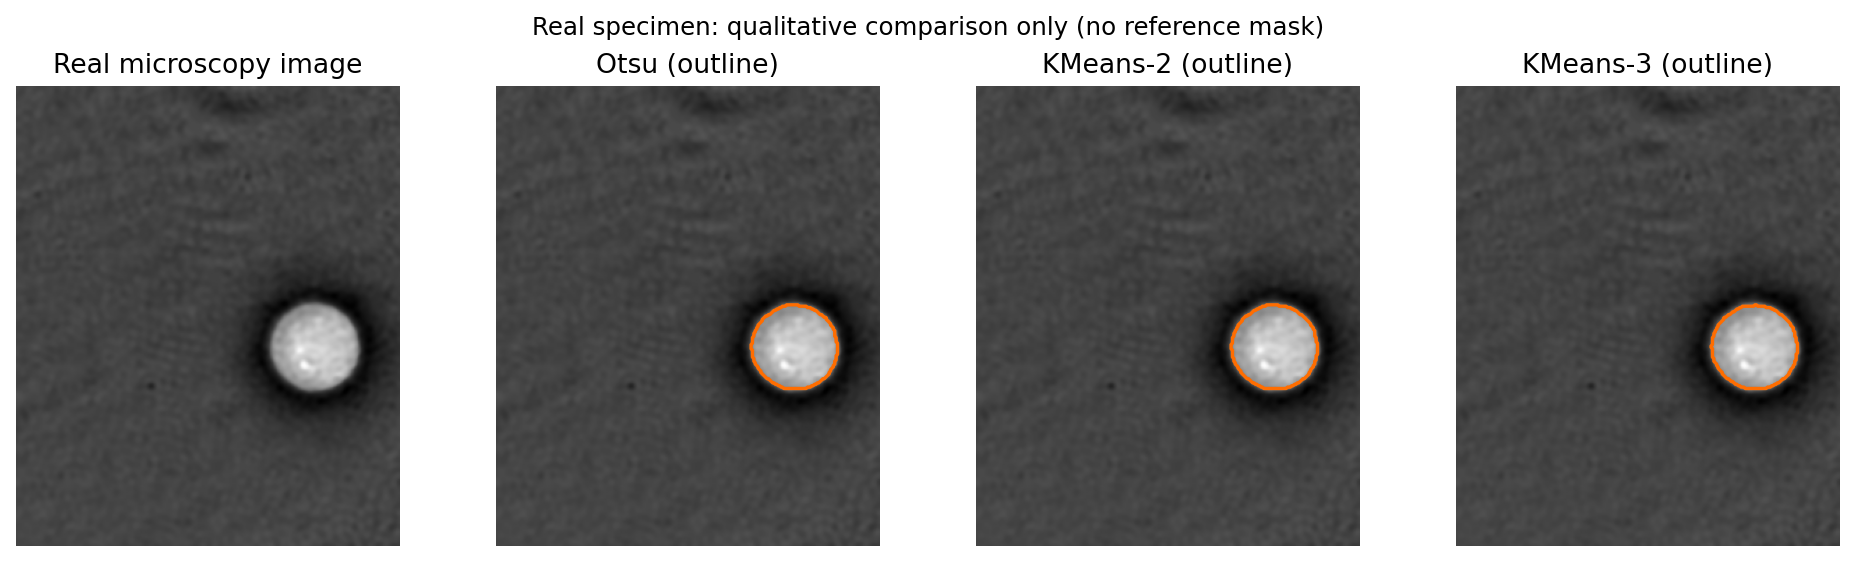

Figure: synthetic_clean_comparison.png


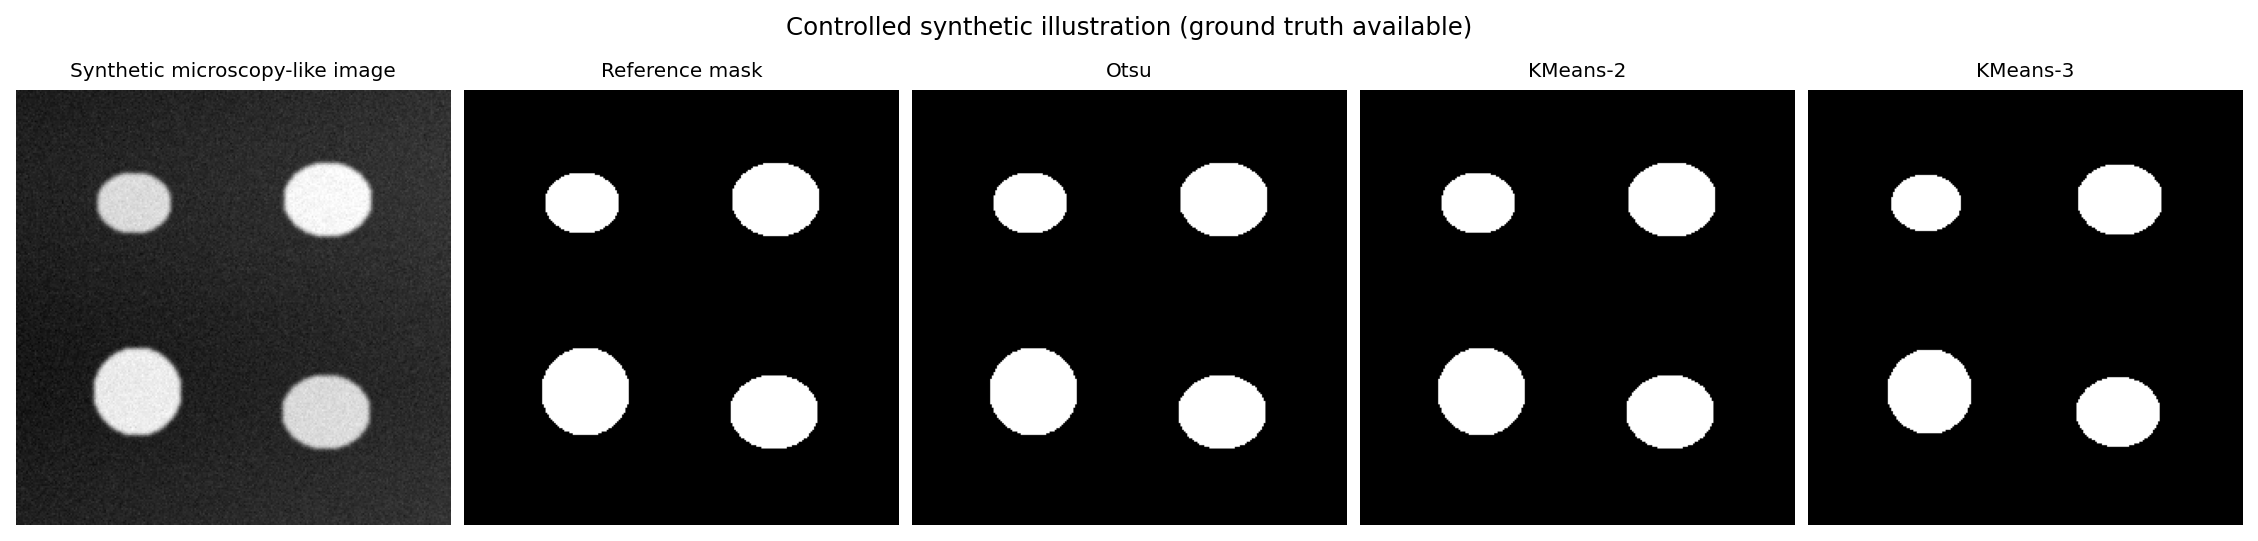

Figure: synthetic_noisy_comparison.png


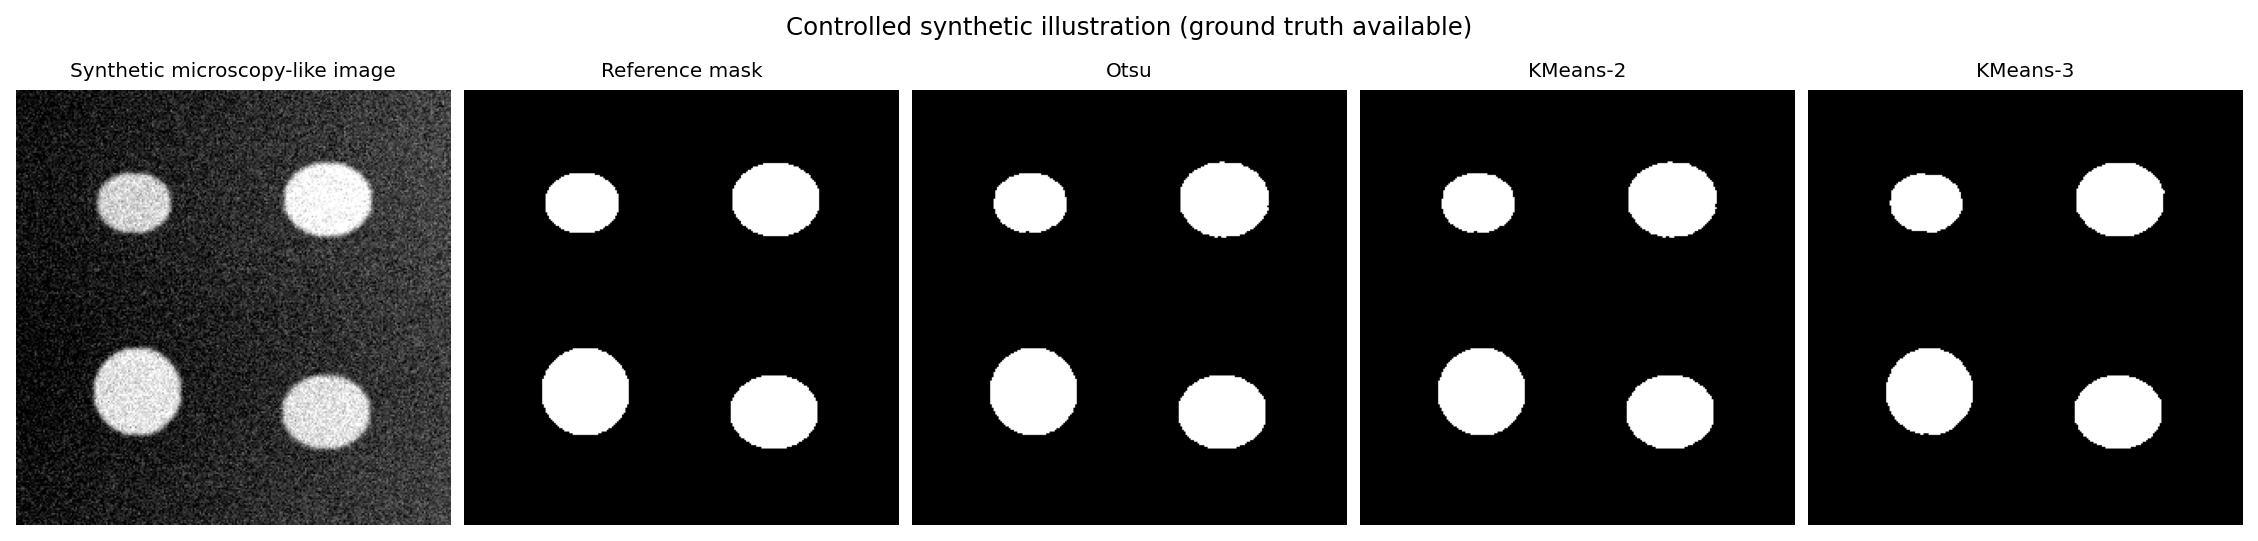

Figure: synthetic_dice_comparison.png


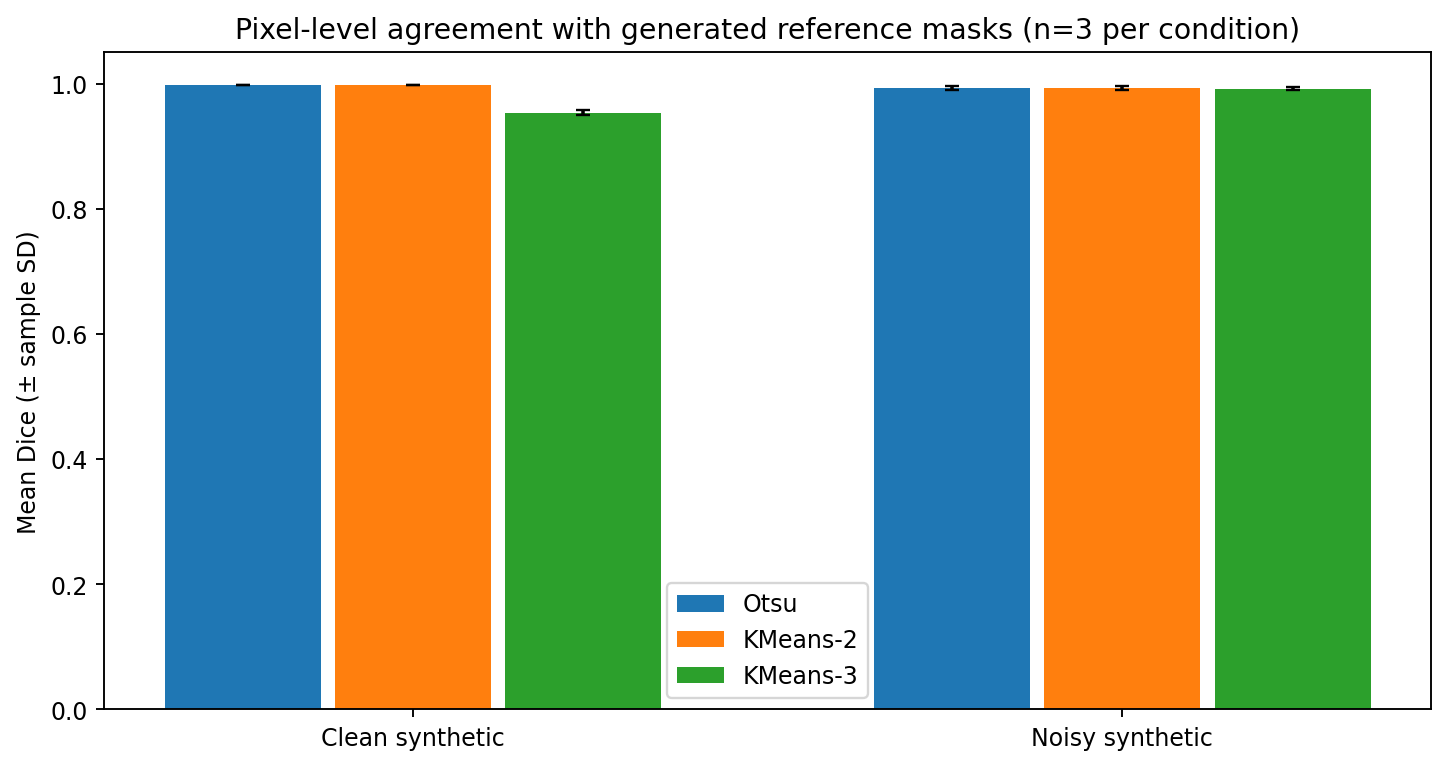

In [9]:
for figure_name in [
    'real_microscopy_comparison.png',
    'synthetic_clean_comparison.png',
    'synthetic_noisy_comparison.png',
    'synthetic_dice_comparison.png',
]:
    print('Figure:', figure_name)
    display(Image(filename=str(OUTPUT / 'figures' / figure_name)))

## 6. Results, validation, and limitations

- Otsu and K-Means (K=2) are expected to perform very similarly on these high-contrast synthetic examples; more clusters do **not** guarantee better segmentation.
- **Do not** report the synthetic Dice/IoU as results for the real specimen.
- The real microscopy assessment is qualitative because we have no verified manual or expert reference mask.
- The synthetic scenes are few, simplified, and have no true cell texture or complex overlap. This is a **small educational demonstration**, not a benchmark of modern cell-segmentation methods.
- The K-Means cluster-to-foreground mapping assumes the target object is the brightest class; this may fail on other modalities and illumination conditions.

**Reproducibility checks:** Results are produced from fixed seeds; rerunning regenerates all figures and CSV files. Cross-environment runtime measurements may vary.

In [10]:
# Three simple integrity checks
assert len(summary) == 6  # 2 synthetic conditions × 3 methods
raw_metrics = pd.read_csv(OUTPUT / 'results' / 'synthetic_pixel_metrics.csv')
assert len(raw_metrics) == 18  # 6 generated images × 3 segmentation algorithms
assert raw_metrics[['dice', 'iou', 'precision', 'recall']].to_numpy().min() >= 0
assert raw_metrics[['dice', 'iou', 'precision', 'recall']].to_numpy().max() <= 1
print('PASS: 18 synthetic evaluations, 6 summary rows, all metrics in [0,1].')
print('CSV outputs:')
for file in sorted((OUTPUT / 'results').glob('*')):
    print('-', file)

PASS: 18 synthetic evaluations, 6 summary rows, all metrics in [0,1].
CSV outputs:
- /mnt/data/kaggle_notebooks_ready/outputs/microscopy_kmeans_outputs/results/environment.json
- /mnt/data/kaggle_notebooks_ready/outputs/microscopy_kmeans_outputs/results/real_microscopy_descriptive.csv
- /mnt/data/kaggle_notebooks_ready/outputs/microscopy_kmeans_outputs/results/summary.csv
- /mnt/data/kaggle_notebooks_ready/outputs/microscopy_kmeans_outputs/results/synthetic_pixel_metrics.csv


## 7. Conclusion and citation

This notebook demonstrates **basic unsupervised learning applied to biomedical images** using intensity clustering. The most defensible conclusion is that simple thresholding and K-Means (K=2) work comparably on these *easy synthetic examples*; a third cluster does not reliably help. Without real-image annotations, further quantitative claims about microscopy performance would be premature.

**Data/software:** `skimage.data.cell()` (scikit-image sample image); synthetic reference masks created here; scikit-learn `KMeans`; scikit-image `threshold_otsu` and morphology. See the scikit-image documentation at https://scikit-image.org/docs/stable/api/skimage.data.html and scikit-learn documentation at https://scikit-learn.org/stable/modules/clustering.html#k-means.

**Suggested CV title:** *Microscopy Image Segmentation Using K-Means Clustering* — Independent Academic Project (2026).